In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("IMDB_Dataset.csv")

print(data.head())
print("Dataset Shape:", data.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Dataset Shape: (50000, 2)


In [3]:
data['sentiment'] = data['sentiment'].map({
    'positive': 1, 'negative': 0
})

X = data['review'].astype(str).values
y = data['sentiment'].values

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
vocab_size = 10000
max_length = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

In [6]:
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 251s 121ms/step - accuracy: 0.7133 - loss: 0.5462 - val_accuracy: 0.5471 - val_loss: 0.6822
Epoch 2/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 116s 58ms/step - accuracy: 0.6772 - loss: 0.5614 - val_accuracy: 0.6009 - val_loss: 0.5961
Epoch 3/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 491s 245ms/step - accuracy: 0.8720 - loss: 0.3204 - val_accuracy: 0.8735 - val_loss: 0.3026
Epoch 4/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 228s 114ms/step - accuracy: 0.9138 - loss: 0.2250 - val_accuracy: 0.8830 - val_loss: 0.2825
Epoch 5/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 286s 143ms/step - accuracy: 0.9357 - loss: 0.1798 - val_accuracy: 0.8821 - val_loss: 0.3444


In [9]:
loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step - accuracy: 0.8849 - loss: 0.3480

Test Loss: 0.34795841574668884
Test Accuracy: 88.49 %


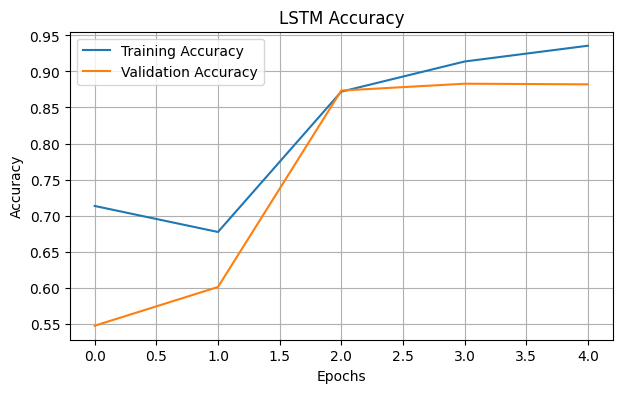

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

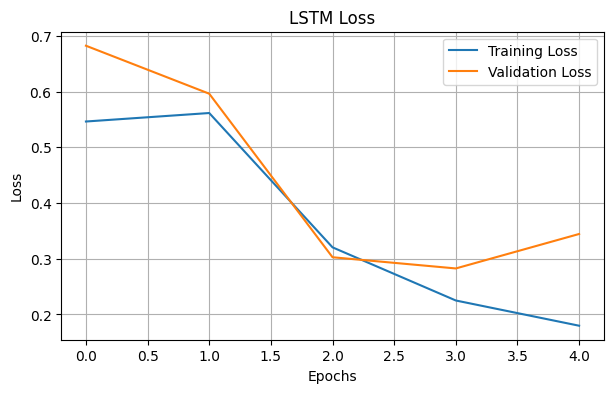

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [12]:
predictions = model.predict(X_test[:5])

print("\nACTUAL VS PREDICTED SENTIMENT")

for i in range(5):
    actual = "Positive" if y_test[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    confidence = predictions[i][0] if predictions[i][0] >= 0.5 else 1-predictions[i][0]

    print(f"\nReview {i+1}")
    print("Actual   :", actual)
    print("Predicted:", predicted)
    print("Probability:", round(float(confidence), 7))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 821ms/step

ACTUAL VS PREDICTED SENTIMENT

Review 1
Actual   : Negative
Predicted: Negative
Probability: 0.9866111

Review 2
Actual   : Negative
Predicted: Negative
Probability: 0.9950343

Review 3
Actual   : Positive
Predicted: Positive
Probability: 0.9903939

Review 4
Actual   : Negative
Predicted: Negative
Probability: 0.9905473

Review 5
Actual   : Negative
Predicted: Negative
Probability: 0.996998


In [13]:
reviews = [
    "This movie was amazing and I really enjoyed it",
    "The movie was boring and disappointing",
    "Excellent acting and wonderful storyline",
    "Worst movie ever, I wasted my time"
]

seq = tokenizer.texts_to_sequences(reviews)
pad = pad_sequences(seq, maxlen=max_length, padding='post')
pred = model.predict(pad)

print("\nCUSTOM REVIEW PREDICTIONS")

for review, p in zip(reviews, pred):
    sentiment = "Positive" if p[0] >= 0.5 else "Negative"
    confidence = p[0] if p[0] >= 0.5 else 1-p[0]

    print("\nReview:", review)
    print("Predicted:", sentiment)
    print("Probability:", round(float(confidence), 7))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 631ms/step

CUSTOM REVIEW PREDICTIONS

Review: This movie was amazing and I really enjoyed it
Predicted: Positive
Probability: 0.9885376

Review: The movie was boring and disappointing
Predicted: Negative
Probability: 0.997113

Review: Excellent acting and wonderful storyline
Predicted: Positive
Probability: 0.9902769

Review: Worst movie ever, I wasted my time
Predicted: Negative
Probability: 0.9972253
